# Pendant-drop capillary shape
## Problem
A photographed water drop hanging from a needle carries information about equilibrium capillary deformation. Recover Bond number, apex pixel geometry, pixel capillary length and the complete modeled silhouette. **No independent physical pixel calibration is available, so absolute surface tension is unidentifiable and is not reported.** Native results are method references, never ground truth.

In [1]:
from pathlib import Path
import sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
if not (ROOT/'src').is_dir():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.main import reconstruct
from src.preprocessing import load_data
from src.visualization import review,robustness
upstream=dict(np.load(ROOT/'notebooks/reference_outputs/upstream.npz'))


## Data
The complete1024×1280grayscale frame and all293native observed contour points are retained. Original Gaussian/Canny processing and contour tracing preceded fitting. The geometric ROI x250:760,y190:720 excludes the solid needle ending near row180; it contains the full visible free-drop body. Duplicate contour points are preserved with native equal weights.

The author manual selects this exact water-in-air image. The associated paper describes experimental measurements for the matching liquid systems and backlit Flea3 CMOS imaging. This frame's camera variant, temperature and metric needle width are not uniquely identified, and are not invented. The public contour is processed measurement, not fitted geometry.

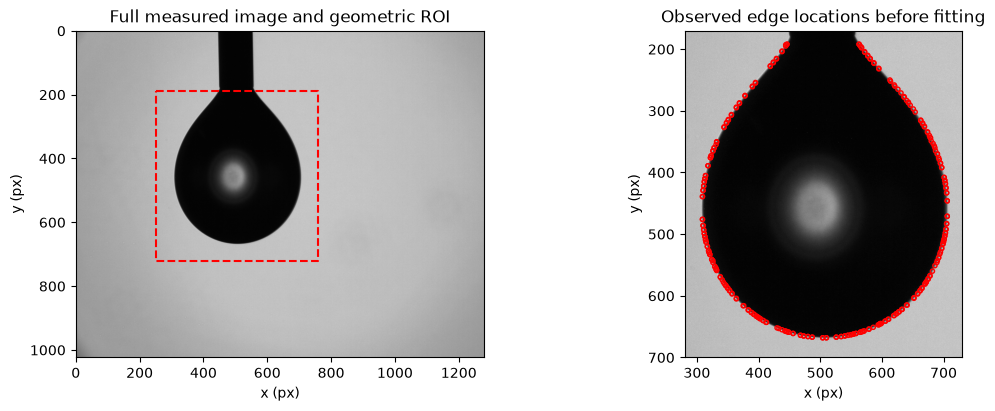

(1024, 1280) (293, 2) unique observed locations 228


In [2]:
image,contour=load_data(ROOT/'data/raw_data.npz')
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained')
ax[0].imshow(image,cmap='gray');ax[0].plot([250,760,760,250,250],[190,190,720,720,190],'r--');ax[0].set(title='Full measured image and geometric ROI',xlabel='x (px)',ylabel='y (px)')
ax[1].imshow(image,cmap='gray');ax[1].scatter(contour[:,0],contour[:,1],s=9,facecolors='none',edgecolors='red');ax[1].set(xlim=(280,730),ylim=(700,170),title='Observed edge locations before fitting',xlabel='x (px)',ylabel='y (px)');plt.show()
print(image.shape,contour.shape,'unique observed locations',len(np.unique(contour,axis=0)))

## Physics
Let $r,z,s$ be dimensionless radius, upward height and arclength scaled by apex radius $R$, and let $\phi$ be tangent angle. The equilibrium equations are
$$r'=\cos\phi,\qquad z'=\sin\phi,\qquad\phi'=2-Bz-\sin\phi/r.$$
$B=\Delta\rho gR_{\rm physical}^2/\gamma$ is the dimensionless Bond number. The apex limit is regular; the implementation initializes $r=10^{-6}$ to avoid division by zero. Rotation and translation map the symmetric profile to image pixels. The recoverable pixel capillary length is $L=R/\sqrt B$. Multiplying an unknown metric pixel size by2would multiply inferred surface tension by4without changing the observed pixel shape: the missing calibration is fundamental.

## Method
The native method initializes from an apex circle, integrates shape and Bond sensitivities, solves a closest-arclength Newton problem for every observed point and performs custom damped normal-equation updates. With signed normal residual vector $e$ and Jacobian $J$, its proposal is
$$\delta=-(J^TJ+\lambda\operatorname{diag}(\operatorname{diag}(J^TJ)))^{-1}J^Te.$$
Here $\lambda$ is damping adjusted by the source's measured reduction rule. Preserve its initialization, acceptance ordering, finite closest-point tolerance and stopping criteria. All293points enter every full fit. Native closest-arclength tolerance corresponds to about0.00019pixel; normal-direction derivatives become noisy for points only~0.001pixel from the curve. This is documented precision behavior, not evidence of a different physical surface. Cross-version quicksort ties are also recorded. No custom iteration is replaced by an opaque domain solver.

In [3]:
started=time.perf_counter();image,contour,result=reconstruct(ROOT/'data/raw_data.npz');elapsed=time.perf_counter()-started
np.savez(ROOT/'output/reconstruction.npz',**{k:result[k][None] for k in ('parameters','reconstruction','capillary_length')})
spec=importlib.util.spec_from_file_location('drop_review_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(ROOT/'output/reconstruction.npz');assert report['passed'],report
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
print('Active full reconstruction seconds:',elapsed)
print(json.dumps(report,indent=2));print('Parameters x,y,R,B,theta:',result['parameters']);print('Pixel capillary length:',result['capillary_length'])


Active full reconstruction seconds: 0.057208299986086786
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "geometry_max": 3.250277512734101e-05,
    "bond_error": 5.771365996221078e-09,
    "angle_error": 1.302038784862375e-07,
    "profile_rmse": 2.1891087468853657e-05,
    "capillary_error": 6.52427377190179e-06,
    "capillary_consistency": 0.0,
    "forward_rms": 2.160139971409553e-05,
    "observation_rms": 0.3726687269188078
  },
  "thresholds": {
    "geometry_max": {
      "comparison": "<=",
      "boundary": 0.02
    },
    "bond_error": {
      "comparison": "<=",
      "boundary": 2e-05
    },
    "angle_error": {
      "comparison": "<=",
      "boundary": 2e-05
    },
    "profile_rmse": {
      "comparison": "<=",
      "boundary": 0.02
    },
    "capillary_error": {
      "comparison": "<=",
      "boundary": 0.05
    },
    "capillary_consistency": {
      "comparison": "<=",
      "boundary": 0.05
    },
    "forward_rms": {
      "comparison": "<=",
      

## Results
Every reconstruction shown below is computed during this notebook. The full frame, complete free contour, signed residuals and all401shape samples are reviewed. Native reference arrays are loaded only for comparisons. The curvature check and Bond sensitivities expose the capillary physics directly; numerical agreement alone is not claimed as physical truth.

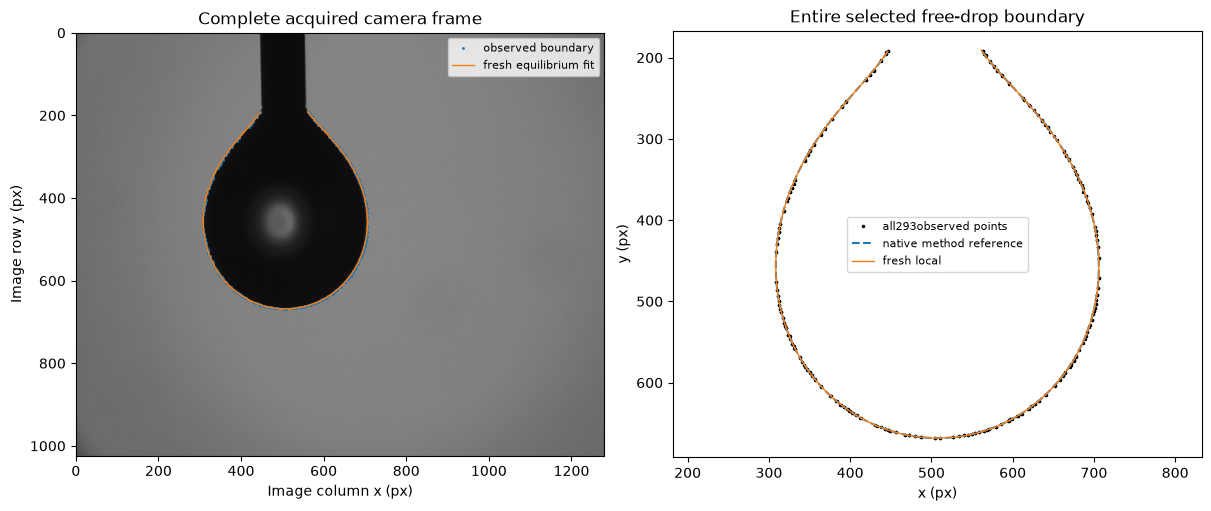

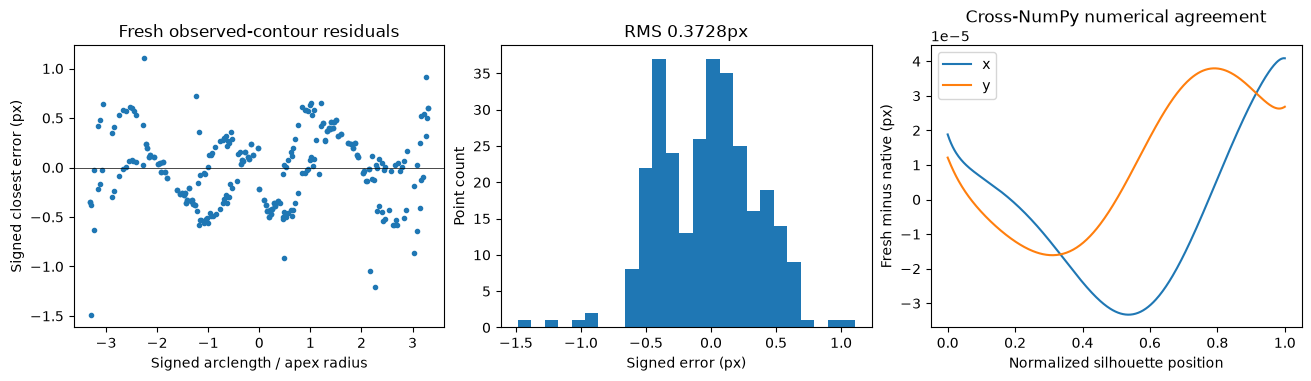

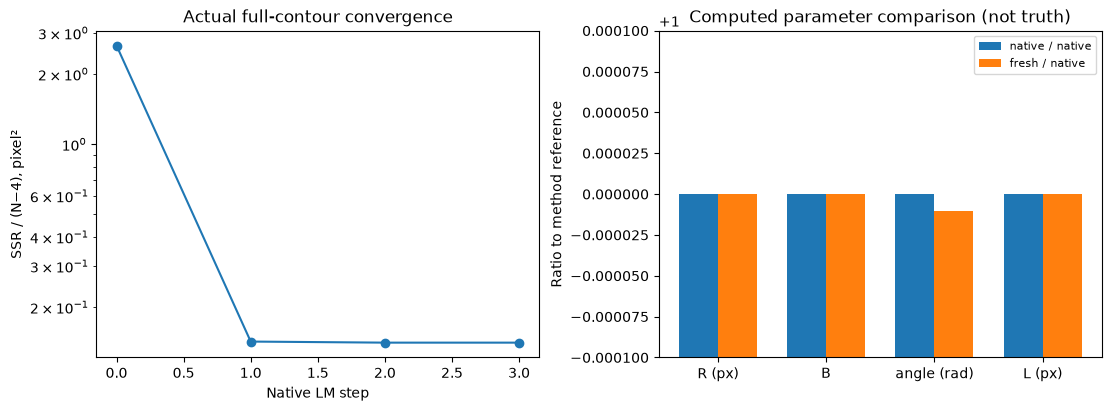

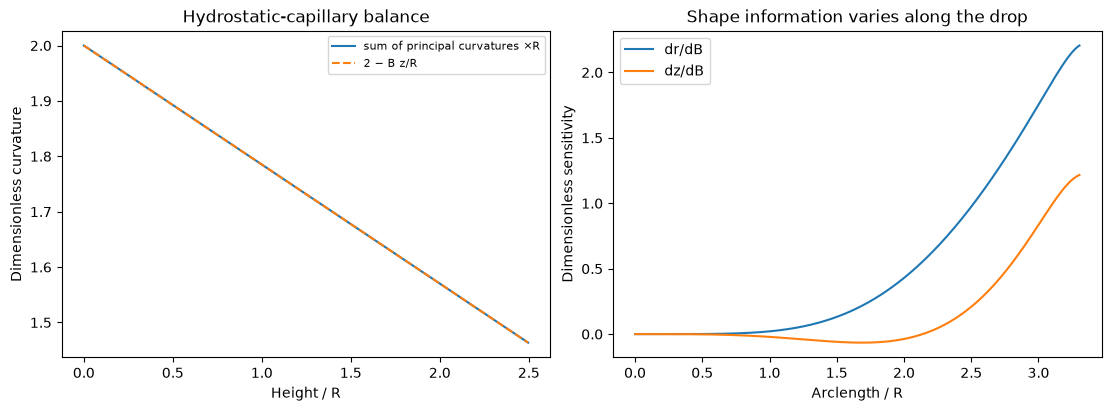

| Quantity | Native reproduced | Fresh local | Unit |
|---|---|---|---|
|apex x|509.942728|509.942696|px|
|apex y|668.214373|668.214373|px|
|apex radius|191.017306|191.017307|px|
|Bond|0.21489617|0.214896164|dimensionless|
|image angle|0.0127924471|0.0127923169|rad|

In [4]:
for fig in review(image,contour,result,upstream):display(fig);plt.close(fig)
lines=['| Quantity | Native reproduced | Fresh local | Unit |','|---|---|---|---|']
for name,u,v,unit in zip(['apex x','apex y','apex radius','Bond','image angle'],upstream['parameters'],result['parameters'],['px','px','px','dimensionless','rad']):lines.append(f'|{name}|{u:.9g}|{v:.9g}|{unit}|')
display(Markdown('\n'.join(lines)))


Predeclared supplementary experiments refit actual observed subsets with image y≥350and y≥450pixels. They illustrate loss of the upper-drop information; the benchmark still uses the entire293point contour. A separately computed least-squares circle is a gravity-free diagnostic, not an omitted native method filled with zeros. All resulting parameters and failures would be shown; no subset is selected by target agreement.

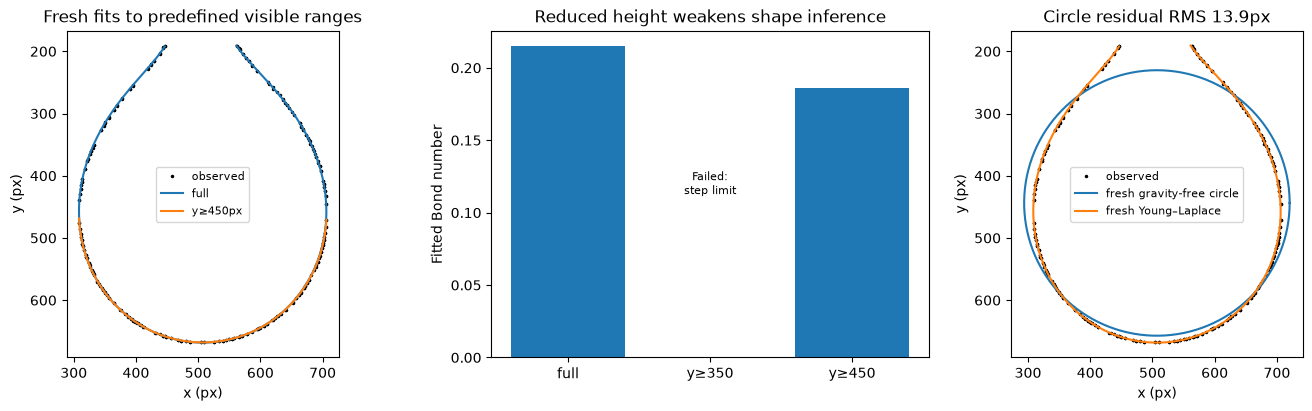

Fresh restricted-height fits (threshold, count, parameters): [(350, 222, 'Native fitting step limit reached'), (450, 173, [506.1828874012913, 667.8986764036341, 192.3238788069283, 0.1859347293206291, -0.006056562209186769])]
Fresh all-point circle center/radius: [507.11874579 443.74483824 213.35082808]


In [5]:
fig,truncations,circle=robustness(contour,result);display(fig);plt.close(fig)
print('Fresh restricted-height fits (threshold, count, parameters):',truncations)
print('Fresh all-point circle center/radius:',circle)


## Conclusion
The observed contour supports a converged Young–Laplace capillary shape with subpixel residuals. Native and cleaned results agree within the predeclared numerical tolerances, and an independent evaluator checks both equilibrium consistency and all observed points. Restricted-height fits and the circle comparison show why gravitational deformation and visibility matter. The result remains a dimensionless and pixel-scale inference: no absolute surface tension, exact physical pixel size, independently known shape or noise calibration has been invented.